# NYC Taxi Trip Duration Prediction

## Project Overview

This project develops a machine learning regression model to predict NYC taxi trip duration in seconds using trip location, pickup time, passenger information, and engineered features.

The workflow covers data cleaning, exploratory data analysis (EDA), feature engineering, chronological data splitting, preprocessing, model comparison, hyperparameter tuning, and final model evaluation.

### Objectives

- Explore trip duration patterns and identify data quality issues.

- Engineer geographic and temporal features to improve predictions.

- Compare regression models using MAE, RMSE, and (R^2).

- Select and evaluate a final model on an unseen test set.

- Build a reusable prediction function for new taxi trips.

## 1. Import Libraries and Set Up the Environment

The project uses Python's data science and machine learning ecosystem.
The notebook also uses geographic calculations and K-Means clustering to construct features representing trip distance and pickup/dropoff areas.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import KFold, cross_validate

## 2. Load the Dataset and Inspect Its Structure

The dataset was obtained from Kaggle: [NYC Taxi Trip Duration](https://www.kaggle.com/datasets/yasserh/nyc-taxi-trip-duration).

The initial dataset contains approximately 1.46 million taxi trips. Each record represents an individual trip and includes pickup and dropoff coordinates, pickup and dropoff timestamps, passenger count, vendor information, and the recorded trip duration.

The initial inspection examines:

- Dataset dimensions and column names.
- Data types and missing values.
- Duplicate records.
- Summary statistics for numerical variables.
- The distribution and range of the target variable.

These checks establish the dataset's structure and help identify potential data quality issues before modeling.

### Data Investigation

In [2]:
df = pd.read_csv("data/NYC.csv")

In [3]:
df.shape

(1458644, 11)

In [4]:
df.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 1458644 entries, 0 to 1458643
Data columns (total 11 columns):
 #   Column              Non-Null Count    Dtype  
---  ------              --------------    -----  
 0   id                  1458644 non-null  str    
 1   vendor_id           1458644 non-null  int64  
 2   pickup_datetime     1458644 non-null  str    
 3   dropoff_datetime    1458644 non-null  str    
 4   passenger_count     1458644 non-null  int64  
 5   pickup_longitude    1458644 non-null  float64
 6   pickup_latitude     1458644 non-null  float64
 7   dropoff_longitude   1458644 non-null  float64
 8   dropoff_latitude    1458644 non-null  float64
 9   store_and_fwd_flag  1458644 non-null  str    
 10  trip_duration       1458644 non-null  int64  
dtypes: float64(4), int64(3), str(4)
memory usage: 417.3 MB


In [5]:
df.head()

,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,455
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,663
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,2124
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,429
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,435


### Data Quality Understanding

In [6]:
df.isnull().sum()

id                    0
vendor_id             0
pickup_datetime       0
dropoff_datetime      0
passenger_count       0
pickup_longitude      0
pickup_latitude       0
dropoff_longitude     0
dropoff_latitude      0
store_and_fwd_flag    0
trip_duration         0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df['id'].duplicated().sum()

np.int64(0)

In [9]:
df[[
    'pickup_longitude',
    'pickup_latitude',
    'dropoff_longitude',
    'dropoff_latitude'
]].describe()

,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude
count,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06
mean,-7.397349e+01,4.075092e+01,-7.397342e+01,4.075180e+01
std,7.090186e-02,3.288119e-02,7.064327e-02,3.589056e-02
min,-1.219333e+02,3.435970e+01,-1.219333e+02,3.218114e+01
25%,-7.399187e+01,4.073735e+01,-7.399133e+01,4.073588e+01
50%,-7.398174e+01,4.075410e+01,-7.397975e+01,4.075452e+01
75%,-7.396733e+01,4.076836e+01,-7.396301e+01,4.076981e+01
max,-6.133553e+01,5.188108e+01,-6.133553e+01,4.392103e+01


### Target Distribution

In [10]:
df['trip_duration'].describe()

count    1.458644e+06
mean     9.594923e+02
std      5.237432e+03
min      1.000000e+00
25%      3.970000e+02
50%      6.620000e+02
75%      1.075000e+03
max      3.526282e+06
Name: trip_duration, dtype: float64

In [11]:
df["trip_duration"].quantile([0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 0.999])

0.010       87.000
0.050      180.000
0.250      397.000
0.500      662.000
0.750     1075.000
0.950     2104.000
0.990     3440.000
0.999    85128.357
Name: trip_duration, dtype: float64

In [12]:
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])
df['dropoff_datetime'] = pd.to_datetime(df['dropoff_datetime'])

In [13]:
calculated_duration = (df['dropoff_datetime'] - df['pickup_datetime']).dt.total_seconds()

In [14]:
(df['trip_duration'] != calculated_duration).sum()

np.int64(0)

In [15]:
for min in [1, 2, 5, 60, 120, 180, 300]:
  count = (df['trip_duration'] > min * 60).sum()
  print(f'>{min:>3} minutes: {count:,}')

>  1 minutes: 1,449,867
>  2 minutes: 1,430,326
>  5 minutes: 1,236,728
> 60 minutes: 12,317
>120 minutes: 2,253
>180 minutes: 2,112
>300 minutes: 2,072


In [16]:
for sec in [1, 2, 5, 10, 30, 60]:
  count = (df['trip_duration'] < sec).sum()
  print(f'<{sec:>2} seconds: {count:,}')

< 1 seconds: 0
< 2 seconds: 33
< 5 seconds: 845
<10 seconds: 1,984
<30 seconds: 4,782
<60 seconds: 8,595


### Haversine Formula

In [17]:
lat1 = np.radians(df['pickup_latitude'])
lon1 = np.radians(df['pickup_longitude'])
lat2 = np.radians(df['dropoff_latitude'])
lon2 = np.radians(df['dropoff_longitude'])

dlat = lat2 - lat1
dlon = lon2 - lon1

a = (np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2)

c = 2 * np.arcsin(np.sqrt(a))

df["distance_km"] = 6371 * c

In [18]:
df['distance_km'].describe()

count    1.458644e+06
mean     3.440864e+00
std      4.296538e+00
min      0.000000e+00
25%      1.231837e+00
50%      2.093717e+00
75%      3.875337e+00
max      1.240909e+03
Name: distance_km, dtype: float64

In [19]:
df['distance_km'].quantile([0.001, 0.01, 0.25, 0.50, 0.75, 0.99, 0.999, 0.9999])

0.0010     0.000000
0.0100     0.139022
0.2500     1.231837
0.5000     2.093717
0.7500     3.875337
0.9900    20.787519
0.9990    24.766758
0.9999    42.610967
Name: distance_km, dtype: float64

In [20]:
df.loc[df['distance_km'].nlargest(10).index,[
        'id',
        'pickup_datetime',
        'dropoff_datetime',
        'pickup_longitude',
        'pickup_latitude',
        'dropoff_longitude',
        'dropoff_latitude',
        'trip_duration'
]].sort_values('trip_duration')

,id,pickup_datetime,dropoff_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,trip_duration
377068,id0116374,2016-04-02 20:33:19,2016-04-02 20:38:01,-74.007095,40.717113,-76.963242,38.946033,282
910072,id1146400,2016-02-15 18:57:32,2016-02-15 19:02:35,-73.989914,40.756634,-70.346077,36.398121,303
974378,id1510552,2016-01-06 20:40:52,2016-01-06 20:51:03,-71.799896,35.081532,-79.352837,40.436329,611
184925,id2306955,2016-05-07 18:58:53,2016-05-07 19:12:05,-72.809669,51.881084,-73.987228,40.750599,792
644165,id0401529,2016-06-02 15:19:35,2016-06-02 15:32:59,-73.980751,40.757111,-74.240051,38.478298,804
275644,id0978162,2016-02-24 16:20:59,2016-02-24 16:35:34,-75.354332,34.712234,-73.834923,32.181141,875
1013474,id3626673,2016-05-05 18:02:50,2016-05-05 18:18:23,-73.978912,40.756763,-79.338699,41.427902,933
923793,id1001696,2016-02-24 21:02:32,2016-02-24 21:25:57,-73.972366,40.758633,-79.553535,43.674000,1405
397526,id0982904,2016-04-28 13:32:14,2016-04-28 14:14:09,-73.870682,40.773598,-79.817978,38.963852,2515
1100676,id2644780,2016-05-03 16:24:07,2016-05-03 17:18:34,-73.991325,40.750023,-79.518616,43.921028,3267


In [21]:
df.loc[df['distance_km'].nsmallest(10).index,[
        'id',
        'pickup_datetime',
        'dropoff_datetime',
        'pickup_longitude',
        'pickup_latitude',
        'dropoff_longitude',
        'dropoff_latitude',
        'trip_duration'
]].sort_values('trip_duration')

,id,pickup_datetime,dropoff_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,trip_duration
2441,id2251007,2016-05-23 14:20:49,2016-05-23 14:20:57,-73.781830,40.644699,-73.781830,40.644699,8
1728,id2134482,2016-01-22 16:13:01,2016-01-22 16:13:20,-73.776314,40.645454,-73.776314,40.645454,19
1620,id0753277,2016-01-27 22:29:31,2016-01-27 22:29:58,-74.209854,40.816853,-74.209854,40.816853,27
246,id3487442,2016-02-29 18:39:12,2016-02-29 18:42:59,-73.981819,40.768963,-73.981819,40.768963,227
2087,id0931199,2016-05-04 22:28:43,2016-05-04 22:32:51,-73.954628,40.777180,-73.954628,40.777180,248
1769,id2892749,2016-01-18 15:24:43,2016-01-18 15:28:57,-73.954666,40.821003,-73.954666,40.821003,254
702,id3499387,2016-01-25 19:45:12,2016-01-25 19:54:52,-73.786720,40.647041,-73.786720,40.647041,580
407,id1145809,2016-05-16 23:15:13,2016-05-16 23:31:00,-73.808487,40.687336,-73.808487,40.687336,947
291,id0924324,2016-05-10 18:07:52,2016-05-10 18:26:21,-73.959068,40.775661,-73.959068,40.775661,1109
2609,id1992673,2016-03-02 20:10:41,2016-03-02 20:30:53,-73.875313,40.773682,-73.875313,40.773682,1212


In [22]:
for dist in [30, 50, 100, 200, 500]:
  count = (df['distance_km'] > dist).sum()
  percentage = count / len(df) * 100
  print(f'> {dist} km: {count:,} {percentage:.4f}')

> 30 km: 573 0.0393
> 50 km: 88 0.0060
> 100 km: 19 0.0013
> 200 km: 11 0.0008
> 500 km: 6 0.0004


In [23]:
df.loc[df['distance_km'] > 100, [
        'pickup_longitude',
        'pickup_latitude',
        'dropoff_longitude',
        'dropoff_latitude',
        'trip_duration',
        'distance_km'
]].sort_values('trip_duration')

,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,trip_duration,distance_km
595540,-78.547401,40.817131,-79.786133,40.917637,279,104.759971
377068,-74.007095,40.717113,-76.963242,38.946033,282,320.125775
910072,-73.989914,40.756634,-70.346077,36.398121,303,578.842818
283102,-73.997086,40.728924,-72.671150,40.614220,427,112.548872
974378,-71.799896,35.081532,-79.352837,40.436329,611,891.214103
184925,-72.809669,51.881084,-73.987228,40.750599,792,1240.908677
644165,-73.980751,40.757111,-74.240051,38.478298,804,254.363523
275644,-75.354332,34.712234,-73.834923,32.181141,875,314.764203
1013474,-73.978912,40.756763,-79.338699,41.427902,933,455.241204
1060807,-66.972160,44.371944,-69.048019,43.147583,1131,215.226573


In [24]:
df['avg_speed_kmh'] = (df['distance_km'] / (df['trip_duration'] / 3600))

In [25]:
df['avg_speed_kmh'].describe(percentiles=[0.001, 0.01, 0.5, 0.99, 0.999])

count    1.458644e+06
mean     1.442321e+01
std      1.497752e+01
min      0.000000e+00
0.1%     0.000000e+00
1%       1.394242e+00
50%      1.279198e+01
99%      4.074530e+01
99.9%    5.430197e+01
max      9.274837e+03
Name: avg_speed_kmh, dtype: float64

In [26]:
df.nlargest(20, 'avg_speed_kmh')[[
        'distance_km',
        'trip_duration',
        'avg_speed_kmh',
        'pickup_longitude',
        'pickup_latitude',
        'dropoff_longitude',
        'dropoff_latitude'
]].sort_values('trip_duration')

,distance_km,trip_duration,avg_speed_kmh,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude
467645,0.231459,1,833.253493,-73.787086,40.647388,-73.789780,40.646992
1001028,0.783347,2,1410.024743,-73.922890,40.858200,-73.925850,40.851521
1107,0.703065,2,1265.516683,-73.827660,40.716175,-73.822113,40.711452
777670,0.912885,3,1095.462175,-73.806503,40.659634,-73.805756,40.651443
1200843,0.760976,3,913.171260,-73.804237,40.662342,-73.807533,40.655972
1322903,1.029739,4,926.765395,-73.998352,40.708530,-73.986382,40.710381
1176337,18.034405,7,9274.836731,-73.936974,40.764610,-73.789848,40.646858
259403,2.526014,10,909.365158,-73.807419,40.657215,-73.783249,40.643806
898154,6.911542,20,1244.077521,-73.815674,40.700844,-73.783714,40.643608
906281,19.948152,51,1408.104838,-73.781860,40.644657,-73.993690,40.724537


In [27]:
for speed in [80, 100, 120, 150, 200]:
  count = (df['avg_speed_kmh'] > speed).sum()
  percentage = count / len(df) * 100
  print(f'> {speed} kmh: {count:,} {percentage:.4f}')

> 80 kmh: 236 0.0162
> 100 kmh: 175 0.0120
> 120 kmh: 136 0.0093
> 150 kmh: 98 0.0067
> 200 kmh: 68 0.0047


In [28]:
df[
    (df['avg_speed_kmh'] > 100) &
    (df['avg_speed_kmh'] <= 150)
][[
        'distance_km',
        'trip_duration',
        'avg_speed_kmh',
        'pickup_longitude',
        'pickup_latitude',
        'dropoff_longitude',
        'dropoff_latitude'
 ]].sort_values('avg_speed_kmh', ascending=False).head(20)

,distance_km,trip_duration,avg_speed_kmh,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude
1086202,0.165914,4,149.322949,-73.989983,40.743050,-73.991707,40.743771
182695,3.210060,79,146.281205,-74.191154,40.654186,-74.170135,40.678253
848976,0.162147,4,145.932460,-73.981682,40.755566,-73.979965,40.754906
313032,0.240743,6,144.445557,-73.750664,40.802101,-73.752296,40.803879
1093421,14.233010,355,144.334748,-73.995918,40.624500,-73.990944,40.752445
803844,0.680954,17,144.202082,-73.941170,40.755070,-73.936554,40.760098
87582,0.439629,11,143.878472,-74.000664,40.747410,-74.003189,40.743950
1034044,0.357530,9,143.011905,-73.776711,40.645351,-73.780151,40.647228
706950,0.396912,10,142.888187,-73.938820,40.750221,-73.942970,40.751911
573454,19.081937,481,142.816994,-73.793633,40.657513,-73.974457,40.760765


In [29]:
for speed in [0.1, 0.5, 1, 2, 3, 5]:
  count = (df['avg_speed_kmh'] < speed).sum()
  percentage = count / len(df) * 100
  print(f'< {speed} kmh: {count:,} {percentage:.4f}')

< 0.1 kmh: 7,994 0.5480
< 0.5 kmh: 11,355 0.7785
< 1 kmh: 13,240 0.9077
< 2 kmh: 17,106 1.1727
< 3 kmh: 24,857 1.7041
< 5 kmh: 71,325 4.8898


In [30]:
df.nsmallest(20, 'avg_speed_kmh')[[
        'distance_km',
        'trip_duration',
        'avg_speed_kmh',
        'pickup_longitude',
        'pickup_latitude',
        'dropoff_longitude',
        'dropoff_latitude'
]].sort_values('trip_duration')

,distance_km,trip_duration,avg_speed_kmh,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude
4892,0.0,5,0.0,-73.982407,40.731144,-73.982407,40.731144
3042,0.0,6,0.0,-73.782715,40.643967,-73.782715,40.643967
2625,0.0,6,0.0,-73.788239,40.641476,-73.788239,40.641476
3261,0.0,7,0.0,-74.177780,40.690281,-74.177780,40.690281
2441,0.0,8,0.0,-73.781830,40.644699,-73.781830,40.644699
4158,0.0,17,0.0,-73.794067,40.657173,-73.794067,40.657173
1728,0.0,19,0.0,-73.776314,40.645454,-73.776314,40.645454
1620,0.0,27,0.0,-74.209854,40.816853,-74.209854,40.816853
246,0.0,227,0.0,-73.981819,40.768963,-73.981819,40.768963
2087,0.0,248,0.0,-73.954628,40.777180,-73.954628,40.777180


In [31]:
speed_invalid = df['avg_speed_kmh'] > 120

print('Invalid speed rows: ', speed_invalid.sum())
print('percentage: ', speed_invalid.mean() * 100)

Invalid speed rows:  136
percentage:  0.009323728065244159


In [32]:
df = df[~speed_invalid].copy()

In [33]:
print('New shape: ', df.shape)
print('Max speed: ', df['avg_speed_kmh'].max())

New shape:  (1458508, 13)
Max speed:  119.75809340128238


In [34]:
for sec in [3600, 7200, 10800, 18000, 36000, 86400]:
  count = (df['trip_duration'] > sec).sum()
  percentage = count / len(df) * 100
  print(
      f'> {sec / 3600:.0f} hour(s)'
      f'{count:,} {percentage:0.4f}'
  )

> 1 hour(s)12,317 0.8445
> 2 hour(s)2,253 0.1545
> 3 hour(s)2,112 0.1448
> 5 hour(s)2,072 0.1421
> 10 hour(s)2,012 0.1379
> 24 hour(s)4 0.0003


In [35]:
df.nlargest(20, 'trip_duration')[[
        'distance_km',
        'trip_duration',
        'avg_speed_kmh',
        'pickup_longitude',
        'pickup_latitude',
        'dropoff_longitude',
        'dropoff_latitude'
]]

,distance_km,trip_duration,avg_speed_kmh,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude
978383,19.900661,3526282,0.020317,-73.783905,40.648632,-73.978271,40.750202
924150,1.635128,2227612,0.002642,-73.983788,40.742325,-73.985489,40.727676
680594,5.982487,2049578,0.010508,-73.921677,40.735252,-73.984749,40.759979
355003,20.148664,1939736,0.037394,-73.789650,40.643559,-73.956810,40.773087
1234291,20.642723,86392,0.860193,-73.794525,40.644825,-73.991051,40.755573
295382,21.117104,86391,0.879971,-73.781952,40.644688,-73.993874,40.745926
73816,2.003924,86390,0.083507,-73.996010,40.753220,-73.979027,40.740601
59891,6.203902,86387,0.258535,-73.992279,40.749729,-73.962524,40.800770
1360439,17.292454,86385,0.720644,-73.782089,40.644806,-73.985016,40.666828
753765,9.824692,86379,0.409462,-74.006111,40.734680,-73.958809,40.815449


In [36]:
df[
    (df['trip_duration'] >= 86000) &
    (df['trip_duration'] < 86400)
]['trip_duration'].describe()

count      883.000000
mean     86220.942242
std        102.055685
min      86002.000000
25%      86144.000000
50%      86242.000000
75%      86308.000000
max      86392.000000
Name: trip_duration, dtype: float64

In [37]:
duration_invalid = df['trip_duration'] >= 86000

print('Invalid duration rows: ', duration_invalid.sum())

combined_invalid = speed_invalid | duration_invalid

print('Combined invalid rows: ', combined_invalid.sum())
print('Percentage: ', combined_invalid.mean())

Invalid duration rows:  887
Combined invalid rows:  1023
Percentage:  0.0007013363096135863


In [38]:
df = df[~duration_invalid].copy()

In [39]:
print('Remaining rows: ', len(df))
print('Max duration: ', df['trip_duration'].max())
print('Max duration hour:', df['trip_duration'].max() / 3600)

Remaining rows:  1457621
Max duration:  85998
Max duration hour: 23.888333333333332


In [40]:
df.isnull().sum().sum()
df.duplicated().sum()

np.int64(0)

### Timestamp Feature Engineering

In [41]:
df['pickup_datetime'].dtype
df['dropoff_datetime'].dtype

dtype('<M8[us]')

In [42]:
print(df['pickup_datetime'].min(), 'to', df['pickup_datetime'].max())
print(df['dropoff_datetime'].min(), 'to', df['dropoff_datetime'].max())

2016-01-01 00:00:17 to 2016-06-30 23:59:39
2016-01-01 00:03:31 to 2016-07-01 20:17:00


In [43]:
df['pickup_hour'] = df['pickup_datetime'].dt.hour
df['pickup_day'] = df['pickup_datetime'].dt.day
df['pickup_dayofweek'] = df['pickup_datetime'].dt.dayofweek
df['pickup_month'] = df['pickup_datetime'].dt.month

In [44]:
df['is_weekend'] = (df['pickup_dayofweek'] >= 5).astype(int)

In [45]:
df['is_rush_hour'] = (
    (df['pickup_dayofweek'] < 5) & (
        df['pickup_hour'].between(7, 9) | df['pickup_hour'].between(16, 19))
).astype(int)

### EDA: Feature Engineering

In [46]:
hour_duration = (df.groupby('pickup_hour')['trip_duration'].agg(['count', 'mean', 'median']))
hour_duration

,count,mean,median
pickup_hour,,,
0,53213,858.681582,646.0
1,38539,843.451205,613.0
2,27955,838.227008,591.0
3,20877,837.149255,592.0
4,15784,895.122402,611.0
5,14995,799.684762,517.0
6,33236,717.723432,473.0
7,55581,805.675896,575.0
8,67015,878.774752,660.0


In [47]:
day_duration = (df.groupby('pickup_dayofweek')['trip_duration'].agg(['count', 'mean', 'median']))
day_duration

,count,mean,median
pickup_dayofweek,,,
0,187314,860.699761,630.0
1,202628,917.079051,678.0
2,210026,937.346562,694.0
3,218434,961.362695,709.0
4,223364,932.675879,685.0
5,220666,851.358184,636.0
6,195189,837.949388,602.0


In [48]:
df[['distance_km', 'trip_duration']].corr()

,distance_km,trip_duration
distance_km,1.000000,0.221621
trip_duration,0.221621,1.000000


In [49]:
df[['pickup_latitude', 'pickup_longitude', 'trip_duration']].corr()

,pickup_latitude,pickup_longitude,trip_duration
pickup_latitude,1.000000,0.018904,-0.064038
pickup_longitude,0.018904,1.000000,0.056680
trip_duration,-0.064038,0.056680,1.000000


In [50]:
df[df['distance_km'] < 0.5][['distance_km', 'trip_duration', 'avg_speed_kmh']].describe()

,distance_km,trip_duration,avg_speed_kmh
count,48807.000000,48807.000000,48807.000000
mean,0.270151,364.447231,7.002813
std,0.179367,2147.218298,7.957373
min,0.000000,1.000000,0.000000
25%,0.070887,92.000000,1.396193
50%,0.324954,178.000000,5.410883
75%,0.431458,332.000000,9.721102
max,0.499995,85984.000000,119.757910


In [51]:
df[df['distance_km'] > 30][['distance_km', 'trip_duration', 'avg_speed_kmh']].describe()

,distance_km,trip_duration,avg_speed_kmh
count,557.000000,557.000000,557.000000
mean,40.279363,3898.346499,43.752529
std,15.348596,5669.000234,12.598499
min,30.001253,1720.000000,1.776497
25%,32.282113,2596.000000,35.339403
50%,35.115484,3157.000000,42.991168
75%,42.284783,4024.000000,52.795300
max,191.402792,85828.000000,81.713718


In [52]:
df[df['trip_duration'] > 36000][[
        'pickup_datetime',
        'dropoff_datetime',
        'distance_km',
        'trip_duration',
        'avg_speed_kmh'
]].head(20)

,pickup_datetime,dropoff_datetime,distance_km,trip_duration,avg_speed_kmh
531,2016-02-20 04:03:06,2016-02-21 03:33:00,2.992817,84594,0.127363
4172,2016-03-18 11:54:20,2016-03-19 11:34:17,2.144412,85197,0.090612
4336,2016-06-08 08:54:33,2016-06-09 07:58:09,0.767894,83016,0.033300
5104,2016-05-05 15:18:41,2016-05-06 15:11:07,1.134700,85946,0.047529
5778,2016-04-02 14:58:45,2016-04-03 14:19:55,1.377784,84070,0.058999
6132,2016-03-15 17:51:32,2016-03-16 17:18:04,1.497237,84392,0.063869
10150,2016-05-09 18:14:42,2016-05-10 17:44:54,10.136107,84612,0.431263
10498,2016-01-08 08:09:48,2016-01-09 07:23:50,1.383503,83642,0.059547
11666,2016-05-20 11:38:47,2016-05-21 11:24:31,3.502102,85544,0.147381
12665,2016-03-25 20:01:22,2016-03-26 19:39:59,4.457450,85117,0.188527


In [53]:
df[df['trip_duration'] > 36000]['avg_speed_kmh'].describe()

count    1125.000000
mean        0.221175
std         0.290522
min         0.000000
25%         0.062110
50%         0.118233
75%         0.243262
max         2.549683
Name: avg_speed_kmh, dtype: float64

In [54]:
invalid_duration = df['trip_duration'] > 36000

df = df[~invalid_duration].copy()
print('Max duration: ', df['trip_duration'].max())

Max duration:  35426


### Feature Engineering

### Manhattan Distance

In [55]:
lat_diff = np.radians(df['dropoff_latitude'] - df['pickup_latitude'])
lon_diff = np.radians(df['dropoff_longitude'] - df['pickup_longitude'])

mean_lat = np.radians((df['dropoff_latitude'] + df['pickup_latitude']) / 2)

lat_distance_km = 6371 * np.abs(lat_diff)

lon_distance_km = (6371 * np.abs(lon_diff) * np.cos(mean_lat))

df['manhattan_distance_km'] = lat_distance_km + lon_distance_km

In [56]:
df[['distance_km', 'manhattan_distance_km', 'trip_duration']].describe()

,distance_km,manhattan_distance_km,trip_duration
count,1.456496e+06,1.456496e+06,1.456496e+06
mean,3.435613e+00,4.439971e+00,8.382710e+02
std,3.951879e+00,5.248468e+00,6.832261e+02
min,0.000000e+00,0.000000e+00,1.000000e+00
25%,1.231824e+00,1.570921e+00,3.970000e+02
50%,2.093397e+00,2.688513e+00,6.620000e+02
75%,3.874518e+00,4.997622e+00,1.073000e+03
max,1.914028e+02,2.413565e+02,3.542600e+04


In [57]:
df[['distance_km', 'manhattan_distance_km', 'trip_duration']].corr()

,distance_km,manhattan_distance_km,trip_duration
distance_km,1.000000,0.994062,0.742802
manhattan_distance_km,0.994062,1.000000,0.731083
trip_duration,0.742802,0.731083,1.000000


### Bearing / Direction

In [58]:
x = np.sin(dlon) * np.cos(lat2)

y = (np.cos(lat1) * np.sin(lat2) - np.sin(lat1) * np.cos(lat2) * np.cos(dlon))

df["bearing"] = (np.degrees(np.arctan2(x, y)) + 360) % 360

In [59]:
df['bearing'].describe()

count    1.456496e+06
mean     1.534055e+02
std      1.042204e+02
min      0.000000e+00
25%      4.430475e+01
50%      1.685184e+02
75%      2.243576e+02
max      3.599935e+02
Name: bearing, dtype: float64

In [60]:
df[['bearing', 'trip_duration']].corr()

,bearing,trip_duration
bearing,1.000000,0.065872
trip_duration,0.065872,1.000000


In [61]:
df['bearing_sin'] = np.sin(np.radians(df['bearing']))
df['bearing_cos'] = np.cos(np.radians(df['bearing']))

### Geographic Clustering: K-Means

In [62]:
coords = df[['pickup_latitude', 'pickup_longitude']]
coords_sample = coords.sample(n = 100_000, random_state=1)

In [63]:
k_values = [10, 20, 30, 40, 50]

inertias = []

for k in k_values:
  kmeans = KMeans(n_clusters=k, random_state=1, n_init=10)
  kmeans.fit(coords_sample)
  inertias.append(kmeans.inertia_)

In [64]:
pd.DataFrame({
    'k': k_values,
    'inertia': inertias
})

,k,inertia
0,10,15.142091
1,20,6.750853
2,30,4.461041
3,40,3.329984
4,50,2.623493


### Cyclic Time Encoding

In [65]:
df['hour_sin'] = np.sin(2 * np.pi * df['pickup_hour'] / 24)
df['hour_cos'] = np.cos(2 * np.pi * df['pickup_hour'] / 24)

In [66]:
df[['pickup_hour', 'hour_sin', 'hour_cos']].drop_duplicates().sort_values('pickup_hour')

,pickup_hour,hour_sin,hour_cos
1,0,0.000000e+00,1.000000e+00
43,1,2.588190e-01,9.659258e-01
20,2,5.000000e-01,8.660254e-01
22,3,7.071068e-01,7.071068e-01
169,4,8.660254e-01,5.000000e-01
149,5,9.659258e-01,2.588190e-01
116,6,1.000000e+00,6.123234e-17
7,7,9.659258e-01,-2.588190e-01
17,8,8.660254e-01,-5.000000e-01
12,9,7.071068e-01,-7.071068e-01


In [67]:
df['dayofweek_sin'] = np.sin(2 * np.pi * df['pickup_dayofweek'] / 7)
df['dayofweek_cos'] = np.cos(2 * np.pi * df['pickup_dayofweek'] / 7)

In [68]:
df[['pickup_dayofweek', 'dayofweek_sin', 'dayofweek_cos']].drop_duplicates().sort_values('pickup_dayofweek')

,pickup_dayofweek,dayofweek_sin,dayofweek_cos
0,0,0.000000,1.000000
2,1,0.781831,0.623490
3,2,0.974928,-0.222521
9,3,0.433884,-0.900969
6,4,-0.433884,-0.900969
4,5,-0.974928,-0.222521
1,6,-0.781831,0.623490


In [69]:
df['route_detour_ratio'] = np.where(
    df['distance_km'] > 0,
    df['manhattan_distance_km'] / (df['distance_km'] + 1e-6),
    0
)

In [70]:
df['route_detour_ratio'].describe()

count    1.456496e+06
mean     1.280896e+00
std      1.432075e-01
min      0.000000e+00
25%      1.202138e+00
50%      1.326697e+00
75%      1.385146e+00
max      1.414215e+00
Name: route_detour_ratio, dtype: float64

In [71]:
df[['route_detour_ratio', 'trip_duration']].corr()

,route_detour_ratio,trip_duration
route_detour_ratio,1.000000,0.009487
trip_duration,0.009487,1.000000


### Model Preparation

In [72]:
model_df = df.drop(columns=['id', 'dropoff_datetime', 'avg_speed_kmh', 'bearing']).copy()

In [73]:
X = model_df.drop(columns='trip_duration')

In [74]:
y = model_df['trip_duration']

In [75]:
print(X.shape, y.shape)

(1456496, 23) (1456496,)


In [76]:
X.dtypes

vendor_id                         int64
pickup_datetime          datetime64[us]
passenger_count                   int64
pickup_longitude                float64
pickup_latitude                 float64
dropoff_longitude               float64
dropoff_latitude                float64
store_and_fwd_flag                  str
distance_km                     float64
pickup_hour                       int32
pickup_day                        int32
pickup_dayofweek                  int32
pickup_month                      int32
is_weekend                        int64
is_rush_hour                      int64
manhattan_distance_km           float64
bearing_sin                     float64
bearing_cos                     float64
hour_sin                        float64
hour_cos                        float64
dayofweek_sin                   float64
dayofweek_cos                   float64
route_detour_ratio              float64
dtype: object

### Chronological Splitting

In [77]:
model_df = model_df.sort_values('pickup_datetime').reset_index(drop=True)

In [78]:
n = len(model_df)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df = model_df.iloc[:train_end].copy()
val_df = model_df.iloc[train_end:val_end].copy()
test_df = model_df.iloc[val_end:].copy()

In [79]:
print('train', train_df['pickup_datetime'].min(), 'to', train_df['pickup_datetime'].max())
print('val', val_df['pickup_datetime'].min(), 'to', val_df['pickup_datetime'].max())
print('test', test_df['pickup_datetime'].min(), 'to', test_df['pickup_datetime'].max())

train 2016-01-01 00:00:17 to 2016-05-06 13:00:47
val 2016-05-06 13:01:20 to 2016-06-02 22:23:03
test 2016-06-02 22:23:16 to 2016-06-30 23:59:39


In [80]:
target = 'trip_duration'

X_train = train_df.drop(columns=[target, 'pickup_datetime'])
y_train = train_df[target]

X_val = val_df.drop(columns=[target, 'pickup_datetime'])
y_val = val_df[target]

X_test = test_df.drop(columns=[target, 'pickup_datetime'])
y_test = test_df[target]

In [81]:
pickup_kmeans = KMeans(n_clusters=50, random_state=1, n_init=10)
dropoff_kmeans = KMeans(n_clusters=50, random_state=1, n_init=10)

In [82]:
pickup_kmeans.fit(X_train[['pickup_latitude', 'pickup_longitude']])
dropoff_kmeans.fit(X_train[['dropoff_latitude', 'dropoff_longitude']])

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",50
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",1
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](50, 2)","[[ 4

In [83]:
X_train['pickup_zone'] = pickup_kmeans.predict(X_train[['pickup_latitude', 'pickup_longitude']])
X_train['dropoff_zone'] = dropoff_kmeans.predict(X_train[['dropoff_latitude', 'dropoff_longitude']])

X_val['pickup_zone'] = pickup_kmeans.predict(X_val[['pickup_latitude', 'pickup_longitude']])
X_val['dropoff_zone'] = dropoff_kmeans.predict(X_val[['dropoff_latitude', 'dropoff_longitude']])

X_test['pickup_zone'] = pickup_kmeans.predict(X_test[['pickup_latitude', 'pickup_longitude']])
X_test['dropoff_zone'] = dropoff_kmeans.predict(X_test[['dropoff_latitude', 'dropoff_longitude']])

In [84]:
print(X_train.shape, X_test.shape, X_val.shape)

(1019547, 24) (218475, 24) (218474, 24)


In [85]:
numeric_features = [
 'passenger_count',
 'pickup_longitude',
 'pickup_latitude',
 'dropoff_longitude',
 'dropoff_latitude',
 'distance_km',
 'pickup_hour',
 'pickup_day',
 'pickup_dayofweek',
 'pickup_month',
 'is_weekend',
 'is_rush_hour',
 'manhattan_distance_km',
 'hour_sin',
 'hour_cos',
 'dayofweek_sin',
 'dayofweek_cos',
 'route_detour_ratio',
 'bearing_sin',
 'bearing_cos']

categorical_features = [
     'vendor_id',
     'store_and_fwd_flag',
     'pickup_zone',
     'dropoff_zone'
 ]

### Preprocessing Transformer

In [86]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

### Hist Gradient Boosting Regressor

In [87]:
hgb_preprocessor = ColumnTransformer(
      transformers=[
          ('num', StandardScaler(), numeric_features),
          ('cat', OneHotEncoder(
              handle_unknown='ignore',
              sparse_output=False,
              dtype=np.float32
          ), categorical_features)
      ]
  )

In [88]:
hgb_tuning_results = pd.DataFrame({
    'Experiment': [
        'Initial',
        'Iteration',
        'Iterations',
        'Learning rate',
        'Leaf nodes',
        'Leaf nodes',
        'Minimum leaf size',
        'L2 regularization',
        'Iterations',
        'Final tuned HGB'
    ],

    'Configuration': [
        '100 iterations, 31 leaves, LR 0.1',
        '200',
        '300, 31 leaves',
        '0.05',
        '15',
        '63',
        '50',
        '1.0',
        '500',
        '700 iterations, LR 0.1, 63 leaves, min leaf size 50, L2 reg 1.0'
    ],

    'MAE(sec)': [
        212.685,
        209.775,
        209.174,
        210.155,
        212.128,
        208.287,
        208.568,
        208.320,
        206.620,
        205.636
    ],

    'RMSE(sec)': [
        392.965,
        384.766,
        383.308,
        387.555,
        388.707,
        381.106,
        380.941,
        380.995,
        379.404,
        378.647
    ],

    'R^2': [
        0.726,
        0.738,
        0.740,
        0.734,
        0.732,
        0.743,
        0.743,
        0.743,
        0.745,
        0.746
    ]
})

hgb_tuning_results

,Experiment,Configuration,MAE(sec),RMSE(sec),R^2
0,Initial,"100 iterations, 31 leaves, LR 0.1",212.685,392.965,0.726
1,Iteration,200,209.775,384.766,0.738
2,Iterations,"300, 31 leaves",209.174,383.308,0.740
3,Learning rate,0.05,210.155,387.555,0.734
4,Leaf nodes,15,212.128,388.707,0.732
5,Leaf nodes,63,208.287,381.106,0.743
6,Minimum leaf size,50,208.568,380.941,0.743
7,L2 regularization,1.0,208.320,380.995,0.743
8,Iterations,500,206.620,379.404,0.745
9,Final tuned HGB,"700 iterations, LR 0.1, 63 leaves, min leaf si...",205.636,378.647,0.746


### XGBregressor Model

### Hyperparametr Tuning

In [89]:
RUN_OLD_MODELS = False

In [90]:
if RUN_OLD_MODELS:
  xgb_lr_result = []

  for learning_rate, n_estimators in [
      (0.10, 200), (0.10, 300), (0.10, 500), (0.05, 300), (0.05, 500), (0.05, 700), (0.03, 700)
  ]:
    model = Pipeline(
            steps=[
                ('preprocessor', preprocessor),
                ('model', XGBRegressor(
                    n_estimators=n_estimators,
                    learning_rate=learning_rate,
                    max_depth=8,
                    min_child_weight=10,
                    subsample=1.0,
                    colsample_bytree=1.0,
                    objective='reg:squarederror',
                    random_state=1,
                    n_jobs=-1
                ))
            ]
          )

    model.fit(X_train, y_train)

    y_val_pred_model = model.predict(X_val)

    mae_model = round(mean_absolute_error(y_val, y_val_pred_model), 3)
    rmse_model = round(np.sqrt(mean_squared_error(y_val, y_val_pred_model)), 3)
    r2_model = round(r2_score(y_val, y_val_pred_model), 3)

    xgb_lr_result.append({
              'learning_rate': learning_rate,
              'n_estimators': n_estimators,
              'MAE': mae_model,
              'RMSE': rmse_model,
              'R2': r2_model
          })

  xgb_lr_result_df = pd.DataFrame(xgb_lr_result)
  xgb_lr_result_df.sort_values('MAE')

In [91]:
xgb_lr = pd.DataFrame({
    'Learning rate': [
        0.10,
        0.10,
        0.10,
        0.05,
        0.05,
        0.05,
        0.03
    ],

    'Estimators': [
        200,
        300,
        500,
        300,
        500,
        700,
        700
    ],

    'MAE(sec)': [
        203.606,
        202.525,
        202.529,
        205.141,
        206.665,
        205.918,
        203.800
    ],

    'RMSE(sec)': [
        380.778,
        379.612,
        379.274,
        381.898,
        380.587,
        379.875,
        380.404
    ],

    'R^2': [
        0.743,
        0.745,
        0.745,
        0.741,
        0.743,
        0.744,
        0.743
    ]
})

xgb_lr.sort_values('MAE(sec)')

,Learning rate,Estimators,MAE(sec),RMSE(sec),R^2
1,0.10,300,202.525,379.612,0.745
2,0.10,500,202.529,379.274,0.745
0,0.10,200,203.606,380.778,0.743
6,0.03,700,203.800,380.404,0.743
3,0.05,300,205.141,381.898,0.741
5,0.05,700,205.918,379.875,0.744
4,0.05,500,206.665,380.587,0.743


In [92]:
if RUN_OLD_MODELS:
  xgb_sampling_result = []

  for subsample, colsample_bytree in [
      (1.0, 1.0), (0.8, 1.0), (1.0, 0.8), (0.8, 0.8)
  ]:
    model = Pipeline(
            steps=[
                ('preprocessor', preprocessor),
                ('model', XGBRegressor(
                    n_estimators=300,
                    learning_rate=0.1,
                    max_depth=8,
                    min_child_weight=10,
                    subsample=subsample,
                    colsample_bytree=colsample_bytree,
                    objective='reg:squarederror',
                    random_state=1,
                    n_jobs=-1
                ))
            ]
          )

    model.fit(X_train, y_train)

    y_val_pred_model = model.predict(X_val)

    mae_model = round(mean_absolute_error(y_val, y_val_pred_model), 3)
    rmse_model = round(np.sqrt(mean_squared_error(y_val, y_val_pred_model)), 3)
    r2_model = round(r2_score(y_val, y_val_pred_model), 3)

    xgb_sampling_result.append({
              'subsample': subsample,
              'colsample_bytree': colsample_bytree,
              'MAE': mae_model,
              'RMSE': rmse_model,
              'R2': r2_model
          })

  xgb_sampling_result_df = pd.DataFrame(xgb_sampling_result)
  xgb_sampling_result_df.sort_values('MAE')

In [93]:
xgb_sampling = pd.DataFrame({
    'subsample': [
        1.0,
        0.8,
        0.8,
        1.0
    ],

    'colsample_bytree': [
        1.0,
        0.8,
        1.0,
        0.8
    ],

    'MAE(sec)': [
        202.525,
        204.426,
        204.587,
        205.706
    ],

    'RMSE(sec)': [
        379.612,
        379.540,
        380.333,
        380.208
    ],

    'R^2': [
        0.745,
        0.745,
        0.744,
        0.744
    ]
})

xgb_sampling.sort_values('MAE(sec)')

,subsample,colsample_bytree,MAE(sec),RMSE(sec),R^2
0,1.0,1.0,202.525,379.612,0.745
1,0.8,0.8,204.426,379.540,0.745
2,0.8,1.0,204.587,380.333,0.744
3,1.0,0.8,205.706,380.208,0.744


In [94]:
if RUN_OLD_MODELS:
  xgb_gamma_result = []

  for gamma in [0, 0.1, 0.5, 1]:
    model = Pipeline(
              steps=[
                  ('preprocessor', preprocessor),
                  ('model', XGBRegressor(
                      n_estimators=300,
                      learning_rate=0.1,
                      max_depth=8,
                      min_child_weight=10,
                      subsample=1.0,
                      colsample_bytree=1.0,
                      gamma=gamma,
                      objective='reg:squarederror',
                      random_state=1,
                      n_jobs=-1
                  ))
              ]
            )

    model.fit(X_train, y_train)

    y_val_pred_model = model.predict(X_val)

    mae_model = round(mean_absolute_error(y_val, y_val_pred_model), 3)
    rmse_model = round(np.sqrt(mean_squared_error(y_val, y_val_pred_model)), 3)
    r2_model = round(r2_score(y_val, y_val_pred_model), 3)

    xgb_gamma_result.append({
                'gamma': gamma,
                'MAE': mae_model,
                'RMSE': rmse_model,
                'R2': r2_model
            })

  xgb_gamma_result_df = pd.DataFrame(xgb_gamma_result)
  xgb_gamma_result_df.sort_values('MAE')

In [95]:
xgb_gamma = pd.DataFrame({
    'gamma': [
        0,
        0.1,
        0.5,
        1.0
    ],

    'MAE(sec)': [
        202.525,
        202.525,
        202.525,
        202.525
    ],

    'RMSE(sec)': [
        379.612,
        379.612,
        379.612,
        379.612
    ],

    'R^2': [
        0.745,
        0.745,
        0.745,
        0.745
    ]
})

xgb_gamma

,gamma,MAE(sec),RMSE(sec),R^2
0,0.0,202.525,379.612,0.745
1,0.1,202.525,379.612,0.745
2,0.5,202.525,379.612,0.745
3,1.0,202.525,379.612,0.745


In [96]:
result = pd.DataFrame([
    {
        'Model': 'Linear Regression',
        'MAE(sec)': 283.994,
        'RMSE(sec)': 465.318,
        'R2': 0.616
    },

    {
        'Model': 'Ridge Regression',
        'MAE(sec)': 283.977,
        'RMSE(sec)': 465.280,
        'R2': 0.616
    },

    {
        'Model': 'Lasso Regression',
        'MAE(sec)': 283.113,
        'RMSE(sec)': 465.682,
        'R2': 0.616
    },

    {
        'Model': 'ElasticNet',
        'MAE(sec)': 290.575,
        'RMSE(sec)': 472.687,
        'R2': 0.604
    },

    {
        'Model': 'Random Forest',
        'MAE(sec)': 220.318,
        'RMSE(sec)': 404.979,
        'R2': 0.709
    },

    {
        'Model': 'HistGradienBoosting(Initial)',
        'MAE(sec)': 212.685,
        'RMSE(sec)': 392.965,
        'R2': 0.726
    },

    {
        'Model': 'HistGradienBoosting(Tuned)',
        'MAE(sec)': 205.636,
        'RMSE(sec)': 378.647,
        'R2': 0.746
    },

    {
        'Model': 'XGBoost(Tuned)',
        'MAE(sec)': 202.525,
        'RMSE(sec)': 379.612,
        'R2': 0.745
    },
])
result

,Model,MAE(sec),RMSE(sec),R2
0,Linear Regression,283.994,465.318,0.616
1,Ridge Regression,283.977,465.280,0.616
2,Lasso Regression,283.113,465.682,0.616
3,ElasticNet,290.575,472.687,0.604
4,Random Forest,220.318,404.979,0.709
5,HistGradienBoosting(Initial),212.685,392.965,0.726
6,HistGradienBoosting(Tuned),205.636,378.647,0.746
7,XGBoost(Tuned),202.525,379.612,0.745


### Final Evaluation

In [97]:
final_xgb_model = Pipeline(
                steps=[
                    ('preprocessor', preprocessor),
                    ('model', XGBRegressor(
                        n_estimators=300,
                        learning_rate=0.1,
                        max_depth=8,
                        min_child_weight=10,
                        subsample=1.0,
                        colsample_bytree=1.0,
                        gamma=0,
                        reg_alpha=0,
                        reg_lambda=1.0,
                        objective='reg:squarederror',
                        random_state=1,
                        n_jobs=-1
                    ))
                ]
              )

In [98]:
final_xgb_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](24,)","['vendor_id','passenger_count','pickup_longitude',...,'route_detour_ratio', 'pickup_zone','dropoff_zone']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,24
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically pass

In [99]:
y_test_pred_xgb = final_xgb_model.predict(X_test)

In [100]:
mae_xgb_test = round(mean_absolute_error(y_test, y_test_pred_xgb), 3)
rmse_xgb_test = round(np.sqrt(mean_squared_error(y_test, y_test_pred_xgb)), 3)
r2_xgb_test = round(r2_score(y_test, y_test_pred_xgb), 3)

print('XGBregressor:')
print('MAE: ', mae_xgb_test)
print('RMSE: ', rmse_xgb_test)
print('R2 score: ', r2_xgb_test)

XGBregressor:
MAE:  199.481
RMSE:  372.043
R2 score:  0.746


In [101]:
if RUN_OLD_MODELS:
  final_hgb_model = Pipeline(
                  steps=[
                      ('preprocessor', hgb_preprocessor),
                      ('model', HistGradientBoostingRegressor(
                          max_iter=700,
                          max_leaf_nodes=63,
                          min_samples_leaf=50,
                          l2_regularization=1.0,
                          random_state=1,
                      ))
                  ]
                )

In [102]:
result_test = pd.DataFrame([
    {
        'Model': 'XGBoost(Test)',
        'MAE(sec)': 199.481,
        'RMSE(sec)': 372.043,
        'R2': 0.746
    },

    {
        'Model': 'HistGradientBoosting(Test)',
        'MAE(sec)': 202.589,
        'RMSE(sec)': 371.212,
        'R2': 0.748
    }
])
result_test

,Model,MAE(sec),RMSE(sec),R2
0,XGBoost(Test),199.481,372.043,0.746
1,HistGradientBoosting(Test),202.589,371.212,0.748


### Residual / Error Analysis

In [103]:
residual_xgb = y_test - y_test_pred_xgb

abs_error_xgb = np.abs(residual_xgb)

In [104]:
residual_summary = pd.DataFrame({
      'Metric': [
          'Mean residual', 'Median residual', 'Std residual', 'MAE', 'RMSE', 'R2'
      ],

      'XGBregressor': [
          residual_xgb.mean(),
          residual_xgb.median(),
          residual_xgb.std(),
          mae_xgb_test,
          rmse_xgb_test,
          r2_xgb_test
      ]
  })

residual_summary

,Metric,XGBregressor
0,Mean residual,4.255933
1,Median residual,-42.686218
2,Std residual,372.019480
3,MAE,199.481000
4,RMSE,372.043000
5,R2,0.746000


### Residual Distribution

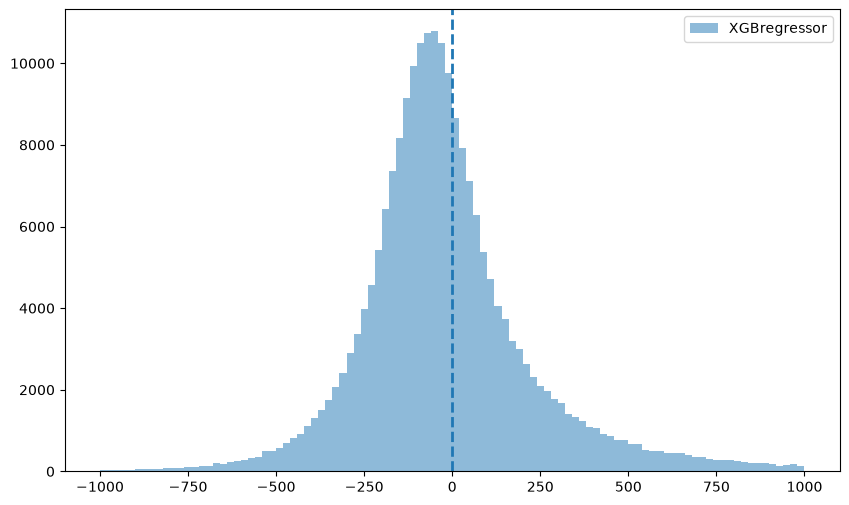

In [105]:
plt.figure(figsize=(10, 6))

plt.hist(residual_xgb, bins=100, range=(-1000, 1000), alpha=0.5, label='XGBregressor')

plt.axvline(0, linestyle='--', linewidth=2)
plt.legend()
plt.show()

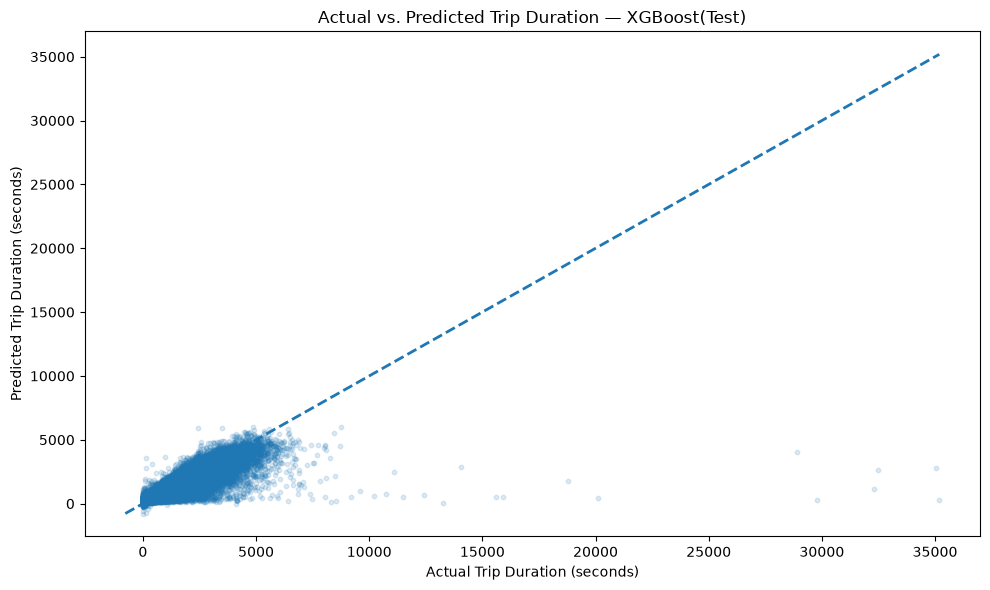

In [106]:
plt.figure(figsize=(10, 6))

plt.scatter(y_test, y_test_pred_xgb, alpha=0.15, s=10)

min_val = np.minimum(y_test.min(), y_test_pred_xgb.min())
max_val = np.maximum(y_test.max(), y_test_pred_xgb.max())

plt.plot([min_val, max_val], [min_val, max_val], linestyle='--', linewidth=2)

plt.xlabel("Actual Trip Duration (seconds)")
plt.ylabel("Predicted Trip Duration (seconds)")
plt.title("Actual vs. Predicted Trip Duration — XGBoost(Test)")
plt.tight_layout()
plt.show()

### Error By Trip Duration

In [107]:
error_analysis = pd.DataFrame({
    'actual': y_test.values,
    'xgb_absolute_error': abs_error_xgb,
    'xgb_residual': residual_xgb
})

In [108]:
error_analysis['duration_bucket'] = pd.cut(
    error_analysis['actual'],
    bins=[0, 600, 1200, 1800, 3600, 7200, np.inf],
    labels=['<10 min', '10-20 min', '20-30 min', '30-60 min', '1-2 hours', '>2 hours'],
    include_lowest=True
)

In [109]:
bucket_result = (
     error_analysis.groupby('duration_bucket', observed=True)
     .agg(
         Count=('actual', 'size'),
         XGB_MAE=('xgb_absolute_error', 'mean'),
         XGB_MEAN_RESIDUAL=('xgb_residual', 'mean')
     ).reset_index()
 )
bucket_result

,duration_bucket,Count,XGB_MAE,XGB_MEAN_RESIDUAL
0,<10 min,93233,116.444814,-82.400737
1,10-20 min,76238,171.788054,-22.426663
2,20-30 min,28997,275.467200,86.847306
3,30-60 min,17793,495.981772,293.447942
4,1-2 hours,2173,1088.322485,981.043681
5,>2 hours,41,10990.444866,10990.444866


In [110]:
bucket_result['percentage'] = (
     bucket_result['Count'] / len(y_test) * 100
 )
bucket_result

,duration_bucket,Count,XGB_MAE,XGB_MEAN_RESIDUAL,percentage
0,<10 min,93233,116.444814,-82.400737,42.674448
1,10-20 min,76238,171.788054,-22.426663,34.895526
2,20-30 min,28997,275.467200,86.847306,13.272457
3,30-60 min,17793,495.981772,293.447942,8.144181
4,1-2 hours,2173,1088.322485,981.043681,0.994622
5,>2 hours,41,10990.444866,10990.444866,0.018766


In [111]:
error_distance = X_test.copy()

error_distance['actual'] = y_test.values
error_distance['xgb_abs_error'] = abs_error_xgb
error_distance['xgb_residual'] = residual_xgb

In [112]:
error_distance['distance_bucket'] = pd.cut(
    error_distance['distance_km'],
    bins=[0, 1, 2, 5, 10, 20, np.inf],
    labels=[
        '<1 km',
        '1-2 km',
        '2-5 km',
        '5-10 km',
        '10-20 km',
        '>20 km'
    ], include_lowest=True
)

In [113]:
distance_result = (
    error_distance.groupby('distance_bucket', observed=True)
    .agg(
        Count=('actual', 'size'),
        XGB_MAE=('xgb_abs_error', 'mean'),
        XGB_MEAN_RESIDUAL=('xgb_residual', 'mean')
    ).reset_index()
)
distance_result

,distance_bucket,Count,XGB_MAE,XGB_MEAN_RESIDUAL
0,<1 km,35365,149.586909,6.995908
1,1-2 km,66600,149.061994,0.836783
2,2-5 km,75666,194.287306,-0.582448
3,5-10 km,26688,279.296256,12.312749
4,10-20 km,10401,413.375101,29.712345
5,>20 km,3755,508.535285,8.816405


In [114]:
error_hour = error_distance.copy()

error_hour['pickup_hour'] = X_test['pickup_hour'].values

In [115]:
hour_result = (
    error_hour.groupby('pickup_hour', observed=True)
    .agg(
        Count=('actual', 'size'),
        XGB_MAE=('xgb_abs_error', 'mean'),
        XGB_MEAN_RESIDUAL=('xgb_residual', 'mean')
    ).reset_index()
)
hour_result

,pickup_hour,Count,XGB_MAE,XGB_MEAN_RESIDUAL
0,0,8750,174.175774,21.784837
1,1,6100,163.673082,-16.275597
2,2,4281,143.745621,-14.705780
3,3,3184,140.240416,-36.043075
4,4,2479,150.136698,-20.223603
5,5,2338,135.041512,-31.892117
6,6,5184,129.907667,-13.730183
7,7,8232,173.778225,-43.356666
8,8,10017,200.916434,-35.443357
9,9,10273,206.704665,-31.030895


In [116]:
error_day = error_distance.copy()

error_day['pickup_dayofweek'] = X_test['pickup_dayofweek'].values

In [117]:
day_result = (
    error_day.groupby('pickup_dayofweek', observed=True)
    .agg(
        Count=('actual', 'size'),
        XGB_MAE=('xgb_abs_error', 'mean'),
        XGB_MEAN_RESIDUAL=('xgb_residual', 'mean')
    ).reset_index()
)
day_result

,pickup_dayofweek,Count,XGB_MAE,XGB_MEAN_RESIDUAL
0,0,28701,178.288034,-17.966798
1,1,30498,195.156699,-8.736453
2,2,31433,225.295325,43.797841
3,3,33306,212.677173,-0.954325
4,4,33033,206.739394,-5.054973
5,5,32802,185.947725,2.247891
6,6,28702,188.794809,16.035716


### XGBregressor 3-fold CV

In [118]:
kf = KFold(n_splits=3, shuffle=True, random_state=1)

In [119]:
xgb_cv = cross_validate(
    final_xgb_model,
    X_train,
    y_train,
    cv=kf,
    scoring={
        'MAE': 'neg_mean_absolute_error',
        'RMSE': 'neg_root_mean_squared_error',
        'R2': 'r2'
    },
    n_jobs=-1,
    return_train_score=False
)

In [120]:
xgb_cv_result = {
    'MAE': round(-xgb_cv['test_MAE'].mean(), 3),
    'RMSE': round(-xgb_cv['test_RMSE'].mean(), 3),
    'R2': round(xgb_cv['test_R2'].mean(), 3)
}
xgb_cv_result

{'MAE': np.float64(169.095),
 'RMSE': np.float64(321.607),
 'R2': np.float64(0.758)}

### Feature Importance

In [121]:
feature_names = preprocessor.get_feature_names_out()
print(len(feature_names))
print(feature_names[:20])

124
['num__passenger_count' 'num__pickup_longitude' 'num__pickup_latitude'
 'num__dropoff_longitude' 'num__dropoff_latitude' 'num__distance_km'
 'num__pickup_hour' 'num__pickup_day' 'num__pickup_dayofweek'
 'num__pickup_month' 'num__is_weekend' 'num__is_rush_hour'
 'num__manhattan_distance_km' 'num__hour_sin' 'num__hour_cos'
 'num__dayofweek_sin' 'num__dayofweek_cos' 'num__route_detour_ratio'
 'num__bearing_sin' 'num__bearing_cos']


In [122]:
xgb_regressor = final_xgb_model.named_steps['model']

feature_importance = pd.DataFrame({
    'feature': feature_names,
    'importance': xgb_regressor.feature_importances_
})

feature_importance = feature_importance.sort_values('importance', ascending=False).reset_index(drop=True)
feature_importance.head(20)

,feature,importance
0,num__distance_km,0.433517
1,num__hour_cos,0.032106
2,num__pickup_dayofweek,0.019014
3,num__pickup_hour,0.018364
4,cat__dropoff_zone_2,0.017697
5,cat__dropoff_zone_8,0.013917
6,num__is_rush_hour,0.012994
7,num__bearing_sin,0.011800
8,num__hour_sin,0.011317
9,num__dayofweek_cos,0.011294


In [123]:
feature_importance['original_feature'] = (
    feature_importance['feature']
    .str.replace(r'^(num|cat)__', '', regex=True)
    .str.replace(r'_\d+$', '', regex=True)
)

In [124]:
aggregated_importance = (
    feature_importance.groupby('original_feature', as_index=False)['importance'].sum()
    .sort_values('importance', ascending=False).reset_index(drop=True)
)
aggregated_importance

,original_feature,importance
0,distance_km,0.433517
1,dropoff_zone,0.224935
2,pickup_zone,0.143174
3,hour_cos,0.032106
4,pickup_dayofweek,0.019014
5,pickup_hour,0.018364
6,is_rush_hour,0.012994
7,bearing_sin,0.011800
8,hour_sin,0.011317
9,dayofweek_cos,0.011294


In [125]:
top_15 = aggregated_importance.head(15).sort_values('importance', ascending=True)

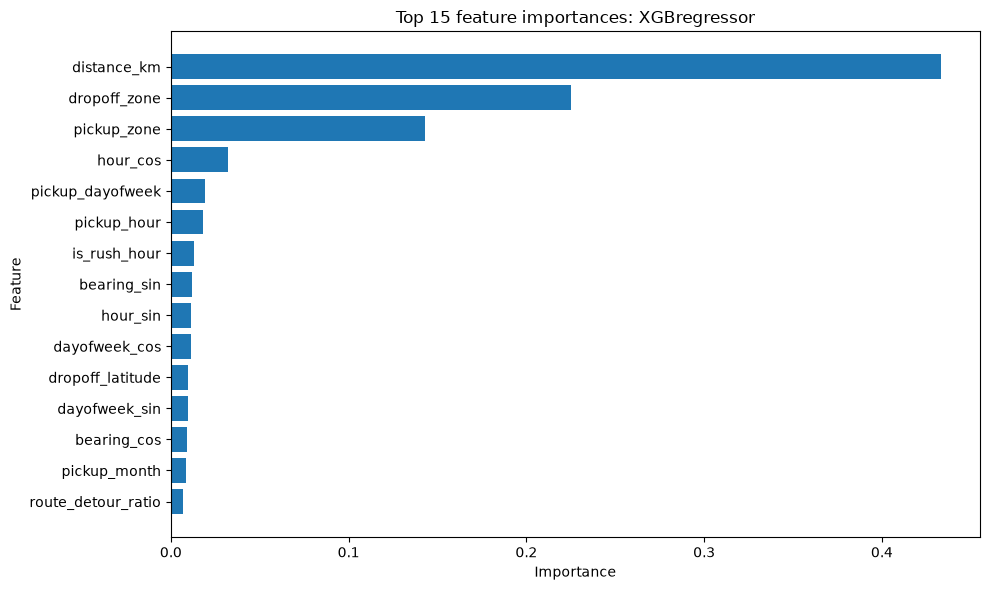

In [126]:
plt.figure(figsize=(10, 6))

plt.barh(top_15['original_feature'], top_15['importance'])

plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Top 15 feature importances: XGBregressor')

plt.tight_layout()

plt.savefig('xgb_feature_importance.png', dpi=300, bbox_inches='tight')

plt.show()

### Final Model Selection

In [127]:
X_train_final = pd.concat([X_train, X_val], axis=0).reset_index(drop=True)
y_train_final = pd.concat([y_train, y_val], axis=0).reset_index(drop=True)

In [128]:
print(X_train_final.shape, y_train_final.shape, X_test.shape, y_test.shape)

(1238021, 24) (1238021,) (218475, 24) (218475,)


In [129]:
X_train_final = X_train_final.drop(columns=['pickup_zone', 'dropoff_zone']).copy()
X_test_final = X_test.drop(columns=['pickup_zone', 'dropoff_zone']).copy()

In [130]:
pickup_kmeans_final = KMeans(n_clusters=50, random_state=1, n_init=10)
dropoff_kmeans_final = KMeans(n_clusters=50, random_state=1, n_init=10)

In [131]:
pickup_kmeans_final.fit(X_train_final[['pickup_latitude', 'pickup_longitude']])
dropoff_kmeans_final.fit(X_train_final[['dropoff_latitude', 'dropoff_longitude']])

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",50
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",1
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](50, 2)","[[ 4

In [132]:
X_train_final['pickup_zone'] = pickup_kmeans_final.predict(X_train_final[['pickup_latitude', 'pickup_longitude']])
X_train_final['dropoff_zone'] = dropoff_kmeans_final.predict(X_train_final[['dropoff_latitude', 'dropoff_longitude']])

In [133]:
X_test_final['pickup_zone'] = pickup_kmeans_final.predict(X_test_final[['pickup_latitude', 'pickup_longitude']])
X_test_final['dropoff_zone'] = dropoff_kmeans_final.predict(X_test_final[['dropoff_latitude', 'dropoff_longitude']])

In [134]:
final_model = Pipeline(
                steps=[
                    ('preprocessor', preprocessor),
                    ('model', XGBRegressor(
                        n_estimators=300,
                        learning_rate=0.1,
                        max_depth=8,
                        min_child_weight=10,
                        subsample=1.0,
                        colsample_bytree=1.0,
                        gamma=0,
                        reg_alpha=0,
                        reg_lambda=1.0,
                        objective='reg:squarederror',
                        random_state=1,
                        n_jobs=-1
                    ))
                ]
              )

In [135]:
final_model.fit(X_train_final, y_train_final)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](24,)","['vendor_id','passenger_count','pickup_longitude',...,'route_detour_ratio', 'pickup_zone','dropoff_zone']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,24
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically pass

In [136]:
y_pred_final = final_model.predict(X_test_final)

In [137]:
mae_final = round(mean_absolute_error(y_test, y_pred_final), 3)
rmse_final = round(np.sqrt(mean_squared_error(y_test, y_pred_final)), 3)
r2_final = round(r2_score(y_test, y_pred_final), 3)

print('Final model:')
print('MAE: ', mae_final)
print('RMSE: ', rmse_final)
print('R2 score: ', r2_final)

Final model:
MAE:  198.827
RMSE:  367.448
R2 score:  0.753


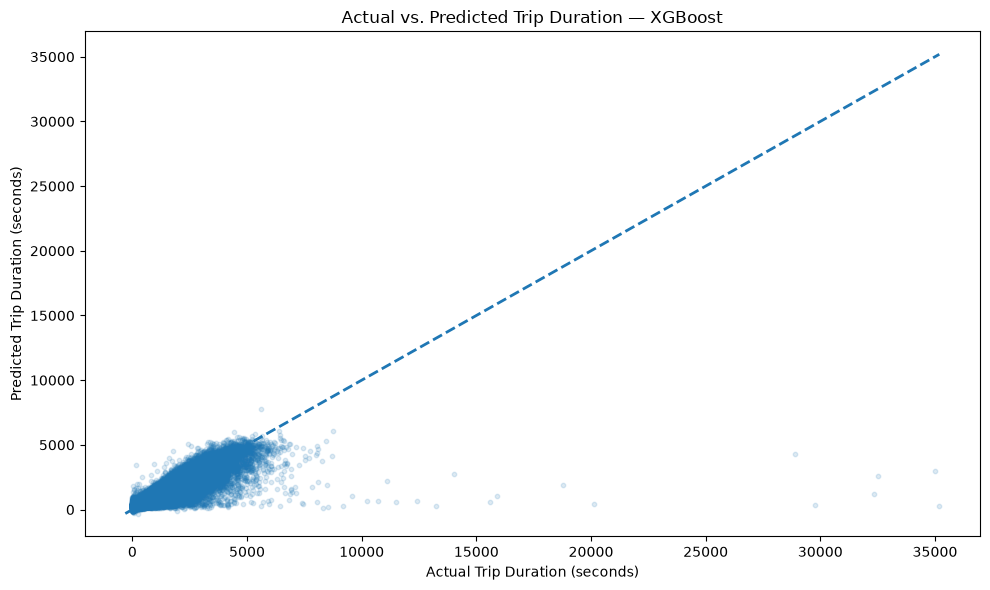

In [138]:
plt.figure(figsize=(10, 6))

plt.scatter(y_test, y_pred_final, alpha=0.15, s=10)

min_val = np.minimum(y_test.min(), y_pred_final.min())
max_val = np.maximum(y_test.max(), y_pred_final.max())

plt.plot([min_val, max_val], [min_val, max_val], linestyle='--', linewidth=2)

plt.xlabel("Actual Trip Duration (seconds)")
plt.ylabel("Predicted Trip Duration (seconds)")
plt.title("Actual vs. Predicted Trip Duration — XGBoost")
plt.tight_layout()
plt.show()

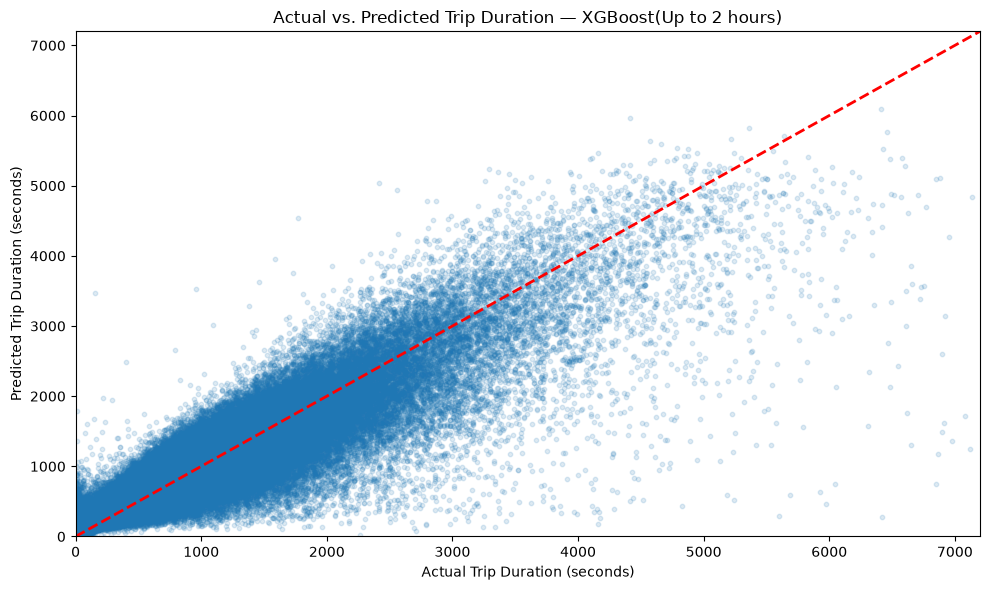

In [139]:
plt.figure(figsize=(10, 6))

plt.scatter(y_test, y_pred_final, alpha=0.15, s=10)

plt.plot([0, 7200], [0, 7200], linestyle='--', linewidth=2, color='red')

plt.xlim(0, 7200)
plt.ylim(0, 7200)

plt.xlabel("Actual Trip Duration (seconds)")
plt.ylabel("Predicted Trip Duration (seconds)")
plt.title("Actual vs. Predicted Trip Duration — XGBoost(Up to 2 hours)")
plt.tight_layout()
plt.show()

### Saving The Model

In [140]:
os.makedirs('models', exist_ok=True)

In [141]:
joblib.dump(final_model, 'models/final_model.joblib')
joblib.dump(pickup_kmeans_final, 'models/pickup_kmeans.joblib')
joblib.dump(dropoff_kmeans_final, 'models/dropoff_kmeans.joblib')

['models/dropoff_kmeans.joblib']

In [142]:
print(os.listdir('models'))

['dropoff_kmeans.joblib', 'final_model.joblib', 'pickup_kmeans.joblib']


### Reusable Prediction Function

In [143]:
final_model = joblib.load('models/final_model.joblib')
pickup_kmeans_final = joblib.load('models/pickup_kmeans.joblib')
dropoff_kmeans_final = joblib.load('models/dropoff_kmeans.joblib')

In [144]:
def predict_trip_duration(
    passenger_count,
    pickup_longitude,
    pickup_latitude,
    dropoff_longitude,
    dropoff_latitude,
    pickup_datetime,
    vendor_id,
    store_and_fwd_flag
):
    # --------------------------------------------------
    # 1. Convert datetime
    # --------------------------------------------------
    pickup_datetime = pd.to_datetime(pickup_datetime)

    pickup_hour = pickup_datetime.hour
    pickup_day = pickup_datetime.day
    pickup_dayofweek = pickup_datetime.dayofweek
    pickup_month = pickup_datetime.month

    # --------------------------------------------------
    # 2. Calendar features
    # --------------------------------------------------
    is_weekend = int(pickup_dayofweek >= 5)

    is_rush_hour = int(
        (pickup_dayofweek < 5)
        and (
            7 <= pickup_hour <= 9
            or 16 <= pickup_hour <= 19
        )
    )

    # --------------------------------------------------
    # 3. Cyclic time features
    # --------------------------------------------------
    hour_sin = np.sin(2 * np.pi * pickup_hour / 24)
    hour_cos = np.cos(2 * np.pi * pickup_hour / 24)

    dayofweek_sin = np.sin(
        2 * np.pi * pickup_dayofweek / 7
    )

    dayofweek_cos = np.cos(
        2 * np.pi * pickup_dayofweek / 7
    )

    # --------------------------------------------------
    # 4. Haversine distance
    # --------------------------------------------------
    lat1 = np.radians(pickup_latitude)
    lon1 = np.radians(pickup_longitude)

    lat2 = np.radians(dropoff_latitude)
    lon2 = np.radians(dropoff_longitude)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2)
    c = 2 * np.arcsin(np.sqrt(a))
    distance_km = 6371 * c

    # --------------------------------------------------
    # 5. Manhattan distance
    # --------------------------------------------------
    lat_diff = np.radians(dropoff_latitude - pickup_latitude)
    lon_diff = np.radians(dropoff_longitude - pickup_longitude)

    mean_lat = np.radians((pickup_latitude + dropoff_latitude) / 2)
    lat_distance_km = 6371 * np.abs(lat_diff)
    lon_distance_km = (6371 * np.abs(lon_diff) * np.cos(mean_lat))
    manhattan_distance_km = (lat_distance_km + lon_distance_km)

    # --------------------------------------------------
    # 6. Bearing
    # --------------------------------------------------
    bearing_x = (np.sin(dlon) * np.cos(lat2))
    bearing_y = (np.cos(lat1) * np.sin(lat2) - np.sin(lat1) * np.cos(lat2) * np.cos(dlon))
    bearing = (np.degrees(np.arctan2(bearing_x, bearing_y)) + 360) % 360
    bearing_rad = np.radians(bearing)
    bearing_sin = np.sin(bearing_rad)
    bearing_cos = np.cos(bearing_rad)

    # --------------------------------------------------
    # 7. Route detour ratio
    # --------------------------------------------------
    if distance_km > 0:
        route_detour_ratio = (
            manhattan_distance_km / distance_km
        )
    else:
        route_detour_ratio = 0

    # --------------------------------------------------
    # 8. Predict spatial zones using final KMeans
    # --------------------------------------------------
    pickup_input = pd.DataFrame([{
        'pickup_latitude': pickup_latitude,
        'pickup_longitude': pickup_longitude
    }])

    dropoff_input = pd.DataFrame([{
        'dropoff_latitude': dropoff_latitude,
        'dropoff_longitude': dropoff_longitude
    }])

    pickup_zone = pickup_kmeans_final.predict(pickup_input)[0]
    dropoff_zone = dropoff_kmeans_final.predict(dropoff_input)[0]

    # --------------------------------------------------
    # 9. Create model input
    # --------------------------------------------------
    input_data = pd.DataFrame([{
        'passenger_count': passenger_count,

        'pickup_longitude': pickup_longitude,
        'pickup_latitude': pickup_latitude,

        'dropoff_longitude': dropoff_longitude,
        'dropoff_latitude': dropoff_latitude,

        'distance_km': distance_km,

        'pickup_hour': pickup_hour,
        'pickup_day': pickup_day,
        'pickup_dayofweek': pickup_dayofweek,
        'pickup_month': pickup_month,

        'is_weekend': is_weekend,
        'is_rush_hour': is_rush_hour,

        'manhattan_distance_km': manhattan_distance_km,

        'hour_sin': hour_sin,
        'hour_cos': hour_cos,

        'dayofweek_sin': dayofweek_sin,
        'dayofweek_cos': dayofweek_cos,

        'route_detour_ratio': route_detour_ratio,

        'bearing_sin': bearing_sin,
        'bearing_cos': bearing_cos,

        'vendor_id': vendor_id,
        'store_and_fwd_flag': store_and_fwd_flag,

        'pickup_zone': pickup_zone,
        'dropoff_zone': dropoff_zone
    }])

    # --------------------------------------------------
    # 10. Make prediction
    # --------------------------------------------------
    prediction_seconds = final_model.predict(
        input_data
    )[0]

    # --------------------------------------------------
    # 11. Convert seconds to minutes
    # --------------------------------------------------
    prediction_minutes = prediction_seconds / 60

    return prediction_seconds, prediction_minutes, input_data

In [145]:
for i in range(1, 5):
    row = test_df.iloc[i]

    function_seconds, function_minutes, _ = predict_trip_duration(
        passenger_count=row["passenger_count"],
        pickup_longitude=row["pickup_longitude"],
        pickup_latitude=row["pickup_latitude"],
        dropoff_longitude=row["dropoff_longitude"],
        dropoff_latitude=row["dropoff_latitude"],
        pickup_datetime=row["pickup_datetime"],
        vendor_id=row["vendor_id"],
        store_and_fwd_flag=row["store_and_fwd_flag"]
    )

    direct_seconds = final_model.predict(X_test_final.iloc[[i]])[0]

    print(f"\nRow {i}")
    print(f"Function prediction: {function_seconds:.6f} seconds")
    print(f"Direct prediction:   {direct_seconds:.6f} seconds")
    print(f"Difference:           {abs(function_seconds - direct_seconds):.10f} seconds")


Row 1
Function prediction: 756.578552 seconds
Direct prediction:   756.578552 seconds
Difference:           0.0000000000 seconds

Row 2
Function prediction: 661.062195 seconds
Direct prediction:   661.062195 seconds
Difference:           0.0000000000 seconds

Row 3
Function prediction: 1297.393799 seconds
Direct prediction:   1297.393799 seconds
Difference:           0.0000000000 seconds

Row 4
Function prediction: 788.830566 seconds
Direct prediction:   788.830566 seconds
Difference:           0.0000000000 seconds
